In [1]:
import numpy as np

def save_amprente_digitale(rotation_angles, noise_patterns, output_path="amprente_digitale.npy"):
    required_chars = ["A", "B", "E", "F", "O", "I", "0", "1", "2", "4", "7", "8"]
    submission_dict = {}
    for ch in required_chars:
        if ch not in rotation_angles:
            raise ValueError(f"Lipseste unghiul pentru caracterul '{ch}'")
        if ch not in noise_patterns:
            raise ValueError(f"Lipseste zgomotul pentru caracterul '{ch}'")
        noise = np.array(noise_patterns[ch])
        if noise.shape != (28, 28):
            raise ValueError(
                f"Zgomotul pentru '{ch}' trebuie sa aibÄƒ dimensiunea (28, 28), dar are {noise.shape}"
            )
        submission_dict[ch] = {
            "angle": float(rotation_angles[ch]),
            "noise": noise
        }
    np.save(output_path, submission_dict, allow_pickle=True)
    return submission_dict

rotation_angles = {
    "A": 7, "B": 25, "E": -10, "F": 0, "O": 10, "I": 0,
    "0": 20, "1": 0, "2": 25, "4": 30, "7": 10, "8": 0
}

mat = np.zeros((28, 28))

for i, row in enumerate(mat):
    for j, pixel in enumerate(row):
        if i > 7 and i < 21 and j > 7 and j < 21:
            mat[i][j] = 15

noise_patterns = {
    ch: mat for ch in rotation_angles
}
subm_dict = save_amprente_digitale(rotation_angles, noise_patterns)

In [2]:
import os
from PIL import Image
from tqdm import tqdm

X = []
train_paths = [path for path in os.listdir("imagini_antrenare") if path.endswith("png")]
for path in tqdm(train_paths):
    img = Image.open(f"imagini_antrenare/{path}")
    img = np.array(img).flatten()
    X.append(img)

X = np.array(X)
X.shape

100%|█████████████████████████████████████████████████████████████████████████████| 6000/6000 [00:09<00:00, 649.94it/s]


(6000, 784)

In [3]:
import torchvision.transforms as T
import pandas as pd

transform = T.Resize((28, 28))

X_final = []
test_paths = [path for path in os.listdir("imagini_suspecte") if path.endswith("png")]
for path in tqdm(test_paths):
    img = Image.open(f"imagini_suspecte/{path}")
    img = transform(img)
    img = np.array(img).flatten()
    X_final.append(img)

X_final = np.array(X_final)
X_final.shape

100%|███████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 672.11it/s]


(200, 784)

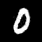

In [4]:
zero_img = Image.open("imagini_antrenare/0_02.png")
unu_img = Image.open("imagini_antrenare/1_02.png")
doi_img = Image.open("imagini_antrenare/2_02.png")
patru_img = Image.open("imagini_antrenare/4_100.png")
sapte_img = Image.open("imagini_antrenare/7_67.png")
opt_img = Image.open("imagini_antrenare/8_17.png")

a_img = Image.open("imagini_antrenare/A_378.png")
b_img = Image.open("imagini_antrenare/B_25.png")
e_img = Image.open("imagini_antrenare/E_15.png")
f_img = Image.open("imagini_antrenare/F_15.png")
o_img = Image.open("imagini_antrenare/O_105.png")
i_img = Image.open("imagini_antrenare/I_30.png")

good_simbols = [zero_img, unu_img, doi_img, patru_img, sapte_img, opt_img, a_img, b_img, e_img, f_img, o_img, i_img]

from skimage.metrics import structural_similarity

thresh = 0.3
def is_good(image):
    image = transform(image)
    sims = []
    for simbol in good_simbols:
        sim = structural_similarity(np.array(image), np.array(simbol))
        sims.append(sim)
    #print(np.argmax(sims))
    #print(max(sims))
    if max(sims) > thresh:
        return 1
    else:
        return 0

img1 = Image.open("imagini_suspecte/task3_006.png")
img1

In [5]:
is_good(img1)

1

In [6]:
labels = []
for path in test_paths:
    img = Image.open(f"imagini_suspecte/{path}")
    labels.append(is_good(img))

In [7]:
df_1 = pd.DataFrame({
    "file": test_paths,
    "subtaskID": 3,
    "class": labels
})

df_1.head()

,file,subtaskID,class
0,task3_000.png,3,1
1,task3_001.png,3,0
2,task3_002.png,3,1
3,task3_003.png,3,0
4,task3_004.png,3,0


In [8]:
sb2_paths = [path for path in os.listdir("parole") if path.endswith("png")]
len(sb2_paths)

300

In [9]:
def is_nr(img):
    img = Image.fromarray(img)
    image = transform(img)
    sims = []
    for simbol in good_simbols:
        sim = structural_similarity(np.array(image), np.array(simbol))
        sims.append(sim)
    idx = np.argmax(sims)
    if idx < 6:
        return "digits"
    return "letters"

(15, 26)
letters


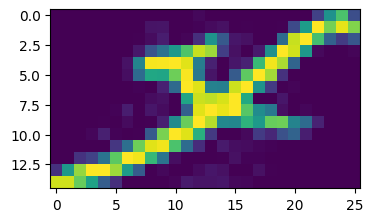

In [16]:
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread(f"parole/{sb2_paths[0]}")
imgray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(imgray, 127, 255, 0)
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

good_cnt = []
for cnt in contours:
    area = cv2.contourArea(cnt)
    if area > 20:
        good_cnt.append(cnt)


x,y,w,h = cv2.boundingRect(good_cnt[2])
small_image = imgray[y:y+h, x:x+w]
print(small_image.shape)
print(is_nr(small_image))
plt.figure(figsize=(4, 4))
plt.imshow(small_image)
plt.show()

In [11]:
def get_labels(path):
    labels = []
    
    img1 = cv2.imread(f"parole/{path}")
    imgray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    ret, thresh = cv2.threshold(imgray, 127, 255, 0)
    contours, hierarchy = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    
    good_cnt = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area > 20:
            good_cnt.append(cnt)
    
    for cnt in good_cnt:
        x,y,w,h = cv2.boundingRect(cnt)
        small_image = imgray[y:y+h, x:x+w]
        labels.append(is_nr(small_image))
    return labels

get_labels(sb2_paths[0])

['letters', 'letters', 'letters', 'digits', 'letters', 'digits']

In [12]:
from tqdm import tqdm
preds = []

for path in tqdm(sb2_paths):
    labels = get_labels(path)
    preds.append(pd.Series(labels).mode()[0])

preds[:5]

100%|████████████████████████████████████████████████████████████████████████████████| 300/300 [00:09<00:00, 31.36it/s]


['letters', 'letters', 'digits', 'digits', 'letters']

In [13]:
df_2 = pd.DataFrame({
    "file": sb2_paths,
    "subtaskID": 4,
    "class": preds
})

df_2.head()

,file,subtaskID,class
0,task4_000.png,4,letters
1,task4_001.png,4,letters
2,task4_002.png,4,digits
3,task4_003.png,4,digits
4,task4_004.png,4,letters


In [14]:
submission = pd.concat([df_1, df_2])
submission

,file,subtaskID,class
0,task3_000.png,3,1
1,task3_001.png,3,0
2,task3_002.png,3,1
3,task3_003.png,3,0
4,task3_004.png,3,0
...,...,...,...
295,task4_295.png,4,letters
296,task4_296.png,4,letters
297,task4_297.png,4,digits
298,task4_298.png,4,digits


In [15]:
submission.to_csv("parole.csv", index=False)